--- GLOBAL NETWORK METRICS ---
Total Packets Generated: 1,731
Total Packets Received: 1,730
Total Packets Dropped: 0
True Packet Delivery Ratio (PDR): 99.94%
Mean End-to-End Delay: 0.0060 s

--- GRANULAR PACKET TRACKING (LIFECYCLE) ---
[!] df_lifecycle is empty. No packets successfully traversed the full Tier1 -> Tier2 path.


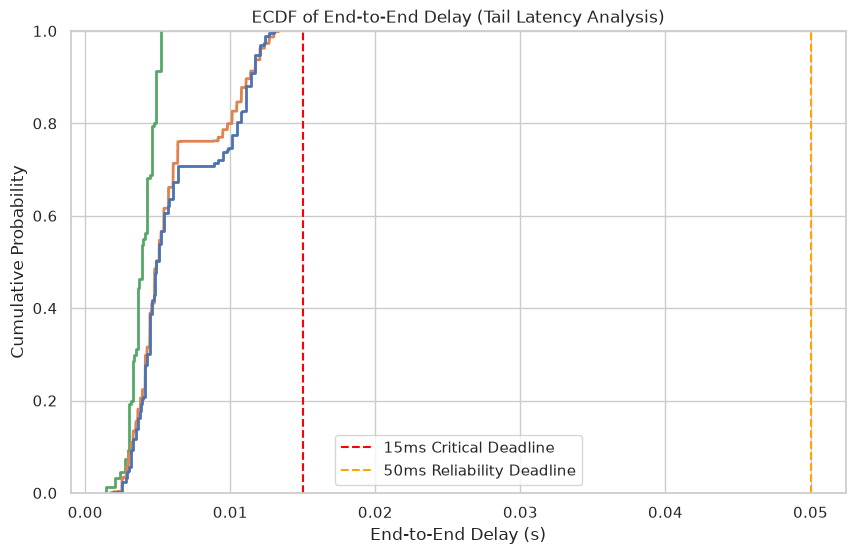

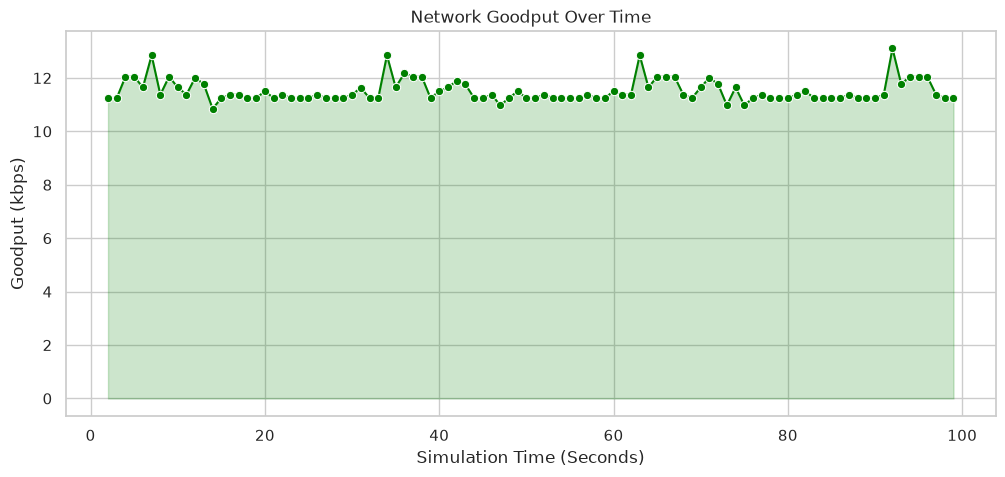

No packet drops recorded.


In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Configure visualization defaults
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (14, 7)
data_dir = Path('../data')

# 1. Load Datasets
df_tx = pd.read_csv(data_dir / "wban_sim_tx.csv")
df_rx = pd.read_csv(data_dir / "wban_sim_lpu_rx.csv")
df_hub = pd.read_csv(data_dir / "wban_sim_hub.csv")
df_drops = pd.read_csv(data_dir / "wban_sim_drops.csv")

prio_map = {0: 'CP (Priority 0)', 1: 'RP (Priority 1)', 2: 'OP (Priority 2)'}
for df in [df_tx, df_rx, df_drops, df_hub]:
    if 'Priority' in df.columns:
        df['QoS_Tag'] = df['Priority'].map(prio_map)

# 2. Corrected Overall Metrics (Accounting for Buffer Drops)
total_generated = len(df_tx) + len(df_drops[df_drops['Layer'] == 'APP']) if not df_drops.empty else len(df_tx)
total_rx = len(df_rx)
true_pdr = (total_rx / total_generated) * 100 if total_generated > 0 else 0

print(f"--- GLOBAL NETWORK METRICS ---")
print(f"Total Packets Generated: {total_generated:,}")
print(f"Total Packets Received: {total_rx:,}")
print(f"Total Packets Dropped: {len(df_drops):,}")
print(f"True Packet Delivery Ratio (PDR): {true_pdr:.2f}%")
if not df_rx.empty:
    print(f"Mean End-to-End Delay: {df_rx['E2EDelay_s'].mean():.4f} s\n")
else:
    print("Mean End-to-End Delay: N/A (0 packets received)\n")

# 3. Packet Lifecycle Decomposer (Tier-1 vs Tier-2 Latency)
print("--- GRANULAR PACKET TRACKING (LIFECYCLE) ---")
if 'NodeID' in df_hub.columns and 'SeqNum' in df_hub.columns:
    # Isolate Hub Rx events (Packet arriving from Sensor to Coordinator)
    hub_rx = df_hub[df_hub['Event'] == 'Rx_802.15.4'].copy()
    hub_rx = hub_rx.rename(columns={'Time_s': 'Time_s_Hub'})

    # Merge Tx (Sensor) -> Hub Rx (Coordinator) -> Rx (LPU)
    df_lifecycle = df_tx.merge(hub_rx[['NodeID', 'SeqNum', 'Time_s_Hub']], on=['NodeID', 'SeqNum'], how='inner')
    df_lifecycle = df_lifecycle.merge(df_rx[['NodeID', 'SeqNum', 'Time_s', 'E2EDelay_s']], on=['NodeID', 'SeqNum'], suffixes=('_Tx', '_Lpu'))
    
    # SAFTEY CHECK: Ensure the intersection is not empty
    if not df_lifecycle.empty:
        df_lifecycle['Tier1_Delay_s'] = df_lifecycle['Time_s_Hub'] - df_lifecycle['Time_s_Tx']
        df_lifecycle['Tier2_Delay_s'] = df_lifecycle['Time_s_Lpu'] - df_lifecycle['Time_s_Hub']
        
        tier1_mean = df_lifecycle.groupby('QoS_Tag')['Tier1_Delay_s'].mean()
        tier2_mean = df_lifecycle.groupby('QoS_Tag')['Tier2_Delay_s'].mean()
        
        print("Mean Tier-1 Latency (Sensor -> Coordinator):")
        print(tier1_mean)
        print("\nMean Tier-2 Latency (Coordinator -> LPU):")
        print(tier2_mean)
        
        # Visualization: Stacked Bar for Segmented Latency
        latency_summary = pd.DataFrame({'Tier 1 (802.15.4)': tier1_mean, 'Tier 2 (WiFi)': tier2_mean}).dropna(how='all')
        if not latency_summary.empty:
            latency_summary.plot(kind='bar', stacked=True, colormap='viridis', figsize=(10, 6))
            plt.title('Segmented Latency Decomposition by QoS Priority')
            plt.ylabel('Mean Delay (seconds)')
            plt.xlabel('Traffic Priority Class')
            plt.xticks(rotation=0)
            plt.show()
        else:
            print("Insufficient data to plot latency summary bar chart.")
    else:
        print("[!] df_lifecycle is empty. No packets successfully traversed the full Tier1 -> Tier2 path.")
else:
    print("Lifecycle tracking requires 'NodeID' and 'SeqNum' in wban_sim_hub.csv.\n")

# 4. ECDF 99th Percentile Tail Latency Analysis
if not df_rx.empty:
    plt.figure(figsize=(10, 6))
    sns.ecdfplot(data=df_rx, x='E2EDelay_s', hue='QoS_Tag', hue_order=['CP (Priority 0)', 'RP (Priority 1)', 'OP (Priority 2)'], linewidth=2)
    plt.axvline(x=0.015, color='red', linestyle='--', label='15ms Critical Deadline')
    plt.axvline(x=0.050, color='orange', linestyle='--', label='50ms Reliability Deadline')
    plt.title('ECDF of End-to-End Delay (Tail Latency Analysis)')
    plt.xlabel('End-to-End Delay (s)')
    plt.ylabel('Cumulative Probability')
    plt.legend()
    plt.show()
else:
    print("[!] Skipping ECDF Plot: No received packets available.")

# 5. Rolling Network Throughput & Goodput (Time-Series)
if not df_rx.empty:
    df_rx_sorted = df_rx.sort_values('Time_s').copy()
    df_rx_sorted['Time_Window'] = df_rx_sorted['Time_s'].astype(int) # Group by 1-second windows
    rolling_goodput = df_rx_sorted.groupby('Time_Window')['Size_bytes'].sum() * 8 / 1000 # kbps

    if not rolling_goodput.empty:
        plt.figure(figsize=(12, 5))
        sns.lineplot(x=rolling_goodput.index, y=rolling_goodput.values, color='green', marker='o')
        plt.title('Network Goodput Over Time')
        plt.xlabel('Simulation Time (Seconds)')
        plt.ylabel('Goodput (kbps)')
        plt.fill_between(rolling_goodput.index, rolling_goodput.values, alpha=0.2, color='green')
        plt.show()
else:
    print("[!] Skipping Goodput Plot: No received packets available.")

# 6. Drop Taxonomy (Time-Series Density)
if not df_drops.empty:
    plt.figure(figsize=(12, 5))
    sns.histplot(data=df_drops, x='Time_s', hue='Layer', multiple='stack', bins=50, palette='magma')
    plt.title('Packet Drop Density Over Time by Network Layer')
    plt.xlabel('Simulation Time (Seconds)')
    plt.ylabel('Drop Count')
    plt.show()
else:
    print("No packet drops recorded.")

Loaded Tx rows: 1731
Loaded Rx rows: 1730
Loaded Drop rows: 0
Loaded Hub rows: 3470

--- GLOBAL NETWORK METRICS ---
Total Packets Generated: 1,731
Total Packets Received: 1,730
Total Packets Dropped: 0 (0 APP, 0 MAC)
True Packet Delivery Ratio (PDR): 99.94%

Overall Mean End-to-End Delay: 0.0060 seconds
Overall Mean Jitter: 0.0032 seconds

Mean Delay & Jitter by Priority:


,E2EDelay_s,Jitter_s
QoS_Tag,,
CP,0.006389,0.003832
OP,0.003921,0.000809
RP,0.006096,0.003237


--- THROUGHPUT ---
Tier-1 MAC Throughput (Sensors -> Hub): 11292.80 bps
Tier-2 App Goodput (Hub -> LPU): 11284.80 bps

--- GRANULAR PACKET TRACKING (LIFECYCLE) ---


/tmp/ipykernel_13619/336959886.py:119: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_rx, x='QoS_Tag', y='E2EDelay_s', order=['CP', 'RP', 'OP'], palette='Set2')


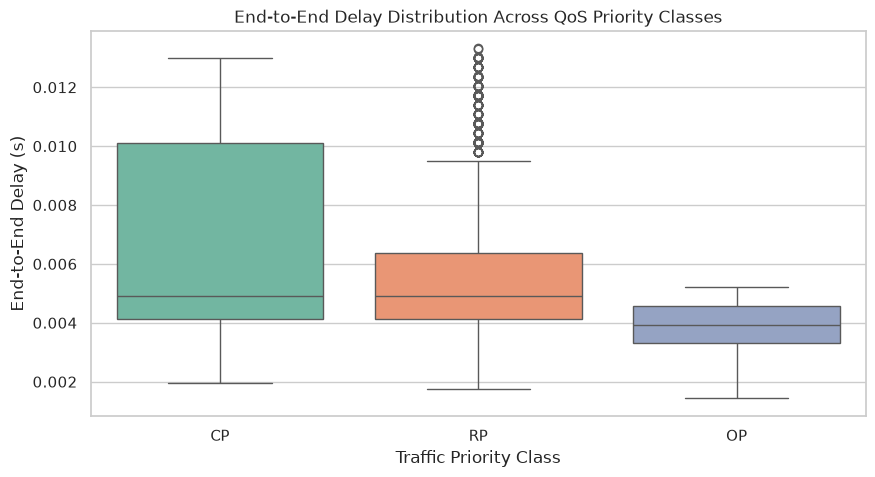

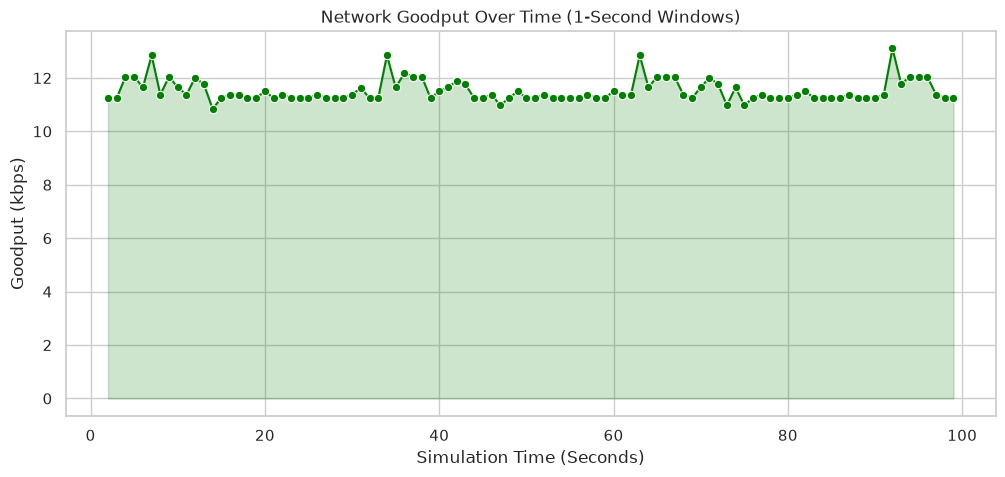

--- PER-NODE PERFORMANCE TABLE ---


,NodeID,SensorName,SensorType,Total_Generated,Tx_Packets,App_Drops,Mac_Drops,Rx_Packets,PDR_%,Mean_Delay_s,Mean_Jitter_s
0,2,EEG,Streaming (P0),400,400,0,0,400,100.0,0.008153,0.005818
1,3,HearingAid,Streaming (P0),200,200,0,0,200,100.0,0.003557,0.000851
2,4,Temperature,Routine (P2),19,19,0,0,19,100.0,0.002819,0.000784
3,5,ECG,Streaming (P0),400,400,0,0,400,100.0,0.008102,0.005888
4,6,BloodPressure,High Event (P1),9,9,0,0,9,100.0,0.002845,0.001089
5,7,InsulinPump,High Event (P1),6,6,0,0,6,100.0,0.002454,0.000454
6,8,SpO2,High Event (P1),98,98,0,0,98,100.0,0.003681,0.000809
7,9,Accelerometer,Routine (P2),200,200,0,0,199,99.5,0.004060,0.000832
8,10,EMG,Streaming (P0),200,200,0,0,200,100.0,0.005251,0.000876
9,11,MotionSensor,Routine (P2),199,199,0,0,199,100.0,0.004105,0.000892



--- PERFORMANCE BY TRAFFIC HIERARCHY TYPE ---


,SensorType,Total_Generated,Tx_Packets,App_Drops,Mac_Drops,Rx_Packets,Mean_Delay_s,Mean_Jitter_s,PDR_%
0,High Event (P1),113,113,0,0,113,0.002994,0.000784,100.000000
1,Routine (P2),418,418,0,0,417,0.003661,0.000836,99.760766
2,Streaming (P0),1200,1200,0,0,1200,0.006266,0.003358,100.000000


/tmp/ipykernel_13619/336959886.py:224: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=node_perf, x='SensorName', y='Mean_Delay_s', ax=ax1, palette='Blues_d', alpha=0.8)


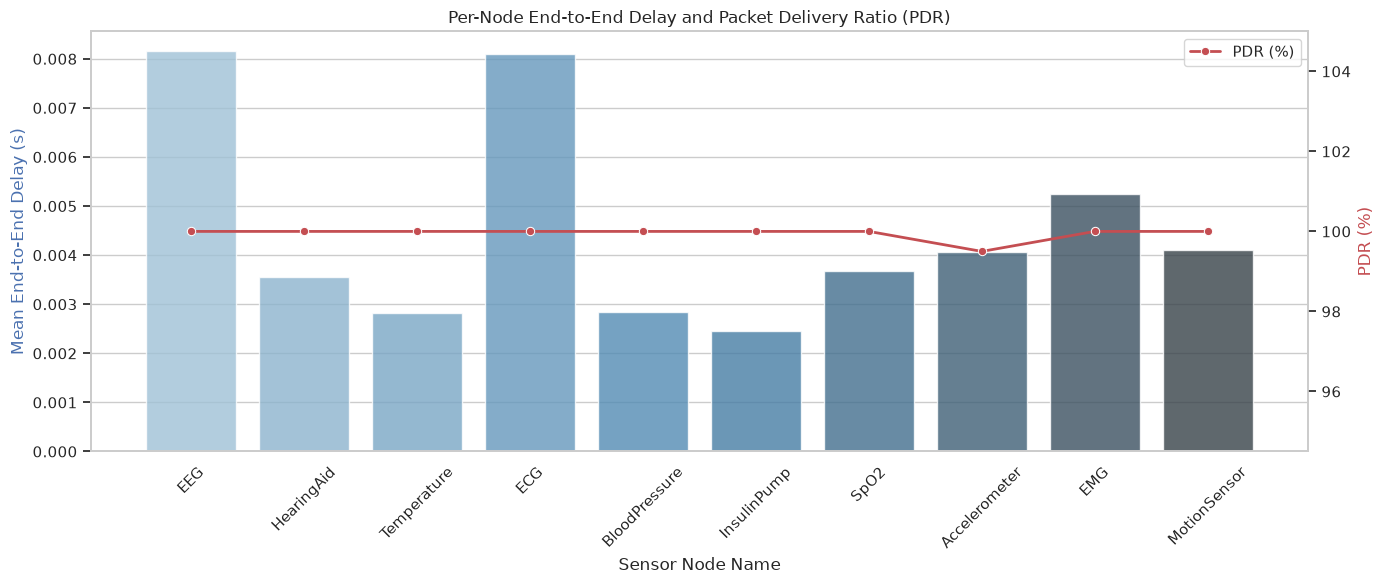

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from IPython.display import display

# Configure visualization defaults
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (14, 7)

data_dir = Path('../data') # Adjust this path as needed

# =============================================================================
# 0. LOAD DATASETS & PREPROCESSING
# =============================================================================
try:
    df_tx = pd.read_csv(data_dir / "wban_sim_tx.csv")
    df_rx = pd.read_csv(data_dir / "wban_sim_lpu_rx.csv")
    df_hub = pd.read_csv(data_dir / "wban_sim_hub.csv")
    df_drops = pd.read_csv(data_dir / "wban_sim_drops.csv")
except FileNotFoundError as e:
    print(f"Error loading datasets. Please check the path: {e}")
    # Initialize empty dataframes to prevent downstream crashes if files are missing
    df_tx, df_rx, df_hub, df_drops = pd.DataFrame(), pd.DataFrame(), pd.DataFrame(), pd.DataFrame()

print(f"Loaded Tx rows: {len(df_tx)}")
print(f"Loaded Rx rows: {len(df_rx)}")
print(f"Loaded Drop rows: {len(df_drops)}")
print(f"Loaded Hub rows: {len(df_hub)}\n")

# Map priority integers to human-readable QoS tags (3-tier)
prio_map = {0: 'CP', 1: 'RP', 2: 'OP'}
for df in [df_tx, df_rx, df_drops, df_hub]:
    if 'Priority' in df.columns and not df.empty:
        df['QoS_Tag'] = df['Priority'].map(prio_map)

if not df_rx.empty:
    df_rx = df_rx.sort_values(by=['NodeID', 'Time_s'])

# =============================================================================
# 1. OVERALL NETWORK METRICS (CORRECTED PDR)
# =============================================================================
# FIX: Only add APP drops to Tx, because MAC drops are already counted in Tx
app_drops = len(df_drops[df_drops['Layer'] == 'APP']) if not df_drops.empty else 0
total_generated = len(df_tx) + app_drops
total_rx = len(df_rx)
pdr = (total_rx / total_generated) * 100 if total_generated > 0 else 0

print(f"--- GLOBAL NETWORK METRICS ---")
print(f"Total Packets Generated: {total_generated:,}")
print(f"Total Packets Received: {total_rx:,}")
print(f"Total Packets Dropped: {len(df_drops):,} ({app_drops} APP, {len(df_drops) - app_drops} MAC)")
print(f"True Packet Delivery Ratio (PDR): {pdr:.2f}%\n")

if not df_rx.empty:
    df_rx['Jitter_s'] = df_rx.groupby('NodeID')['E2EDelay_s'].diff().abs()
    mean_delay = df_rx['E2EDelay_s'].mean()
    mean_jitter = df_rx['Jitter_s'].mean()
    
    print(f"Overall Mean End-to-End Delay: {mean_delay:.4f} seconds")
    print(f"Overall Mean Jitter: {mean_jitter:.4f} seconds")
    print("\nMean Delay & Jitter by Priority:")
    display(df_rx.groupby('QoS_Tag')[['E2EDelay_s', 'Jitter_s']].mean())
else:
    print("End-to-End metrics unavailable (0 packets received).\n")

# =============================================================================
# 2. DATA RATES & THROUGHPUT
# =============================================================================
sim_duration = 100.0 

if not df_rx.empty and not df_hub.empty:
    rx_bytes = df_rx['Size_bytes'].sum()
    goodput_bps = (rx_bytes * 8) / sim_duration
    
    hub_mac_rx = df_hub[df_hub['Event'] == 'Rx_802.15.4']
    mac_bytes = hub_mac_rx['Size_bytes'].sum()
    throughput_bps = (mac_bytes * 8) / sim_duration
    
    print(f"--- THROUGHPUT ---")
    print(f"Tier-1 MAC Throughput (Sensors -> Hub): {throughput_bps:.2f} bps")
    print(f"Tier-2 App Goodput (Hub -> LPU): {goodput_bps:.2f} bps\n")

# =============================================================================
# 3. TIER-1 vs TIER-2 LIFECYCLE DECOMPOSITION
# =============================================================================
if not df_tx.empty and not df_hub.empty and not df_rx.empty:
    print("--- GRANULAR PACKET TRACKING (LIFECYCLE) ---")
    hub_rx = df_hub[df_hub['Event'] == 'Rx_802.15.4'].copy().rename(columns={'Time_s': 'Time_s_Hub'})
    
    # Merge traces by unique NodeID and Sequence Number
    df_lifecycle = df_tx.merge(hub_rx[['NodeID', 'SeqNum', 'Time_s_Hub']], on=['NodeID', 'SeqNum'], how='inner')
    df_lifecycle = df_lifecycle.merge(df_rx[['NodeID', 'SeqNum', 'Time_s', 'E2EDelay_s']], on=['NodeID', 'SeqNum'], suffixes=('_Tx', '_Lpu'))
    
    if not df_lifecycle.empty:
        df_lifecycle['Tier1_Delay_s'] = df_lifecycle['Time_s_Hub'] - df_lifecycle['Time_s_Tx']
        df_lifecycle['Tier2_Delay_s'] = df_lifecycle['Time_s_Lpu'] - df_lifecycle['Time_s_Hub']
        
        tier1_mean = df_lifecycle.groupby('QoS_Tag')['Tier1_Delay_s'].mean()
        tier2_mean = df_lifecycle.groupby('QoS_Tag')['Tier2_Delay_s'].mean()
        
        latency_summary = pd.DataFrame({'Tier 1 (802.15.4)': tier1_mean, 'Tier 2 (WiFi)': tier2_mean}).dropna(how='all')
        
        if not latency_summary.empty:
            latency_summary.plot(kind='bar', stacked=True, colormap='viridis', figsize=(10, 6))
            plt.title('Segmented Latency Decomposition by QoS Priority')
            plt.ylabel('Mean Delay (seconds)')
            plt.xlabel('Traffic Priority Class')
            plt.xticks(rotation=0)
            plt.show()

# =============================================================================
# 4. GLOBAL VISUALIZATIONS & DROP ANALYSIS
# =============================================================================
if not df_rx.empty:
    # 4A. E2E Delay Boxplot
    plt.figure(figsize=(10, 5))
    sns.boxplot(data=df_rx, x='QoS_Tag', y='E2EDelay_s', order=['CP', 'RP', 'OP'], palette='Set2')
    plt.title('End-to-End Delay Distribution Across QoS Priority Classes')
    plt.xlabel('Traffic Priority Class')
    plt.ylabel('End-to-End Delay (s)')
    plt.show()
    
    # 4B. Rolling Goodput over time
    df_rx['Time_Window'] = df_rx['Time_s'].astype(int)
    rolling_goodput = df_rx.groupby('Time_Window')['Size_bytes'].sum() * 8 / 1000 # kbps
    if not rolling_goodput.empty:
        plt.figure(figsize=(12, 5))
        sns.lineplot(x=rolling_goodput.index, y=rolling_goodput.values, color='green', marker='o')
        plt.title('Network Goodput Over Time (1-Second Windows)')
        plt.xlabel('Simulation Time (Seconds)')
        plt.ylabel('Goodput (kbps)')
        plt.fill_between(rolling_goodput.index, rolling_goodput.values, alpha=0.2, color='green')
        plt.show()

if not df_drops.empty:
    print("--- DROP ANALYSIS ---")
    plt.figure(figsize=(10, 5))
    sns.countplot(data=df_drops, x='Layer', hue='QoS_Tag', hue_order=['CP', 'RP', 'OP'], palette='Reds_d')
    plt.title('Packet Drops by Network Layer and QoS Priority')
    plt.xlabel('Drop Layer (APP = Buffer Drop-Tail, MAC = Channel Contention)')
    plt.ylabel('Drop Count')
    plt.legend(title='Priority')
    plt.show()
    
    drop_summary = df_drops.groupby(['NodeID', 'Layer', 'QoS_Tag']).size().reset_index(name='Drop_Count')
    display(drop_summary)

# =============================================================================
# 5. PER-NODE AGGREGATION & PERFORMANCE
# =============================================================================
if not df_tx.empty:
    node_metadata = {
        2: {"SensorName": "EEG", "SensorType": "Streaming (P0)"},
        3: {"SensorName": "HearingAid", "SensorType": "Streaming (P0)"},
        5: {"SensorName": "ECG", "SensorType": "Streaming (P0)"},
        10: {"SensorName": "EMG", "SensorType": "Streaming (P0)"},
        6: {"SensorName": "BloodPressure", "SensorType": "High Event (P1)"},
        7: {"SensorName": "InsulinPump", "SensorType": "High Event (P1)"},
        8: {"SensorName": "SpO2", "SensorType": "High Event (P1)"},
        4: {"SensorName": "Temperature", "SensorType": "Routine (P2)"},
        9: {"SensorName": "Accelerometer", "SensorType": "Routine (P2)"},
        11: {"SensorName": "MotionSensor", "SensorType": "Routine (P2)"}
    }

    tx_node = df_tx.groupby('NodeID').size().reset_index(name='Tx_Packets')
    rx_node = df_rx.groupby('NodeID').size().reset_index(name='Rx_Packets') if not df_rx.empty else pd.DataFrame(columns=['NodeID', 'Rx_Packets'])
    node_perf = pd.merge(tx_node, rx_node, on='NodeID', how='outer').fillna(0)

    if not df_drops.empty:
        # Separate APP drops (never reached Tx) from MAC drops (failed after Tx)
        app_drop_node = df_drops[df_drops['Layer'] == 'APP'].groupby('NodeID').size().reset_index(name='App_Drops')
        mac_drop_node = df_drops[df_drops['Layer'] == 'MAC'].groupby('NodeID').size().reset_index(name='Mac_Drops')
        
        node_perf = pd.merge(node_perf, app_drop_node, on='NodeID', how='left').fillna(0)
        node_perf = pd.merge(node_perf, mac_drop_node, on='NodeID', how='left').fillna(0)
    else:
        node_perf['App_Drops'] = 0
        node_perf['Mac_Drops'] = 0

    # Total intended generation = packets successfully passed to socket (Tx) + packets dropped before socket (App_Drops)
    node_perf['Total_Generated'] = node_perf['Tx_Packets'] + node_perf['App_Drops']
    node_perf['PDR_%'] = (node_perf['Rx_Packets'] / node_perf['Total_Generated']) * 100

    if not df_rx.empty:
        mean_delay_node = df_rx.groupby('NodeID')['E2EDelay_s'].mean().reset_index(name='Mean_Delay_s')
        mean_jitter_node = df_rx.groupby('NodeID')['Jitter_s'].mean().reset_index(name='Mean_Jitter_s')
        node_perf = node_perf.merge(mean_delay_node, on='NodeID', how='left').merge(mean_jitter_node, on='NodeID', how='left')
    else:
        node_perf['Mean_Delay_s'] = np.nan
        node_perf['Mean_Jitter_s'] = np.nan

    node_perf['SensorName'] = node_perf['NodeID'].map(lambda x: node_metadata.get(x, {}).get('SensorName', 'Unknown'))
    node_perf['SensorType'] = node_perf['NodeID'].map(lambda x: node_metadata.get(x, {}).get('SensorType', 'Unknown'))

    node_perf = node_perf[['NodeID', 'SensorName', 'SensorType', 'Total_Generated', 'Tx_Packets', 'App_Drops', 'Mac_Drops', 'Rx_Packets', 'PDR_%', 'Mean_Delay_s', 'Mean_Jitter_s']]
    node_perf = node_perf.sort_values(by='NodeID').reset_index(drop=True)

    print("--- PER-NODE PERFORMANCE TABLE ---")
    display(node_perf)

    type_perf = node_perf.groupby('SensorType').agg({
        'Total_Generated': 'sum',
        'Tx_Packets': 'sum',
        'App_Drops': 'sum',
        'Mac_Drops': 'sum',
        'Rx_Packets': 'sum',
        'Mean_Delay_s': 'mean',
        'Mean_Jitter_s': 'mean'
    }).reset_index()
    
    type_perf['PDR_%'] = (type_perf['Rx_Packets'] / type_perf['Total_Generated']) * 100
    
    print("\n--- PERFORMANCE BY TRAFFIC HIERARCHY TYPE ---")
    display(type_perf)

    # =============================================================================
    # 6. PER-NODE VISUALIZATION
    # =============================================================================
    if not node_perf['Mean_Delay_s'].isna().all():
        fig, ax1 = plt.subplots(figsize=(14, 6))

        sns.barplot(data=node_perf, x='SensorName', y='Mean_Delay_s', ax=ax1, palette='Blues_d', alpha=0.8)
        ax1.set_title('Per-Node End-to-End Delay and Packet Delivery Ratio (PDR)')
        ax1.set_xlabel('Sensor Node Name')
        ax1.set_ylabel('Mean End-to-End Delay (s)', color='b')
        ax1.tick_params(axis='x', rotation=45)

        ax2 = ax1.twinx()
        sns.lineplot(data=node_perf, x='SensorName', y='PDR_%', ax=ax2, color='r', marker='o', linewidth=2, label='PDR (%)')
        ax2.set_ylabel('PDR (%)', color='r')

        min_pdr = node_perf['PDR_%'].min()
        ax2.set_ylim(max(0, min_pdr - 5), 105) 
        ax2.grid(False)

        plt.tight_layout()
        plt.show()